# Notebook 03: Audio Preprocessing, Encoding & Experiments
### Multidimensional Emotion-to-Sentiment Derivation System

**Assigned Scope: Audio Modality Pipeline**

This notebook implements the complete audio processing pipeline mandated by `AGENTS.md`:
1. **Audio Extraction & Standardization**: Extract audio from EmoReact `.mp4` clips $\rightarrow$ standard 16 kHz mono.
2. **Acoustic Representation**: Extract 64-band Log-Mel Spectrograms using `torchaudio`.
3. **PyTorch Audio Dataset**: Create an `EmoReactAudioDataset` and `DataLoader` with batching.
4. **`AudioEncoder` Architecture**: Build a lightweight CNN backbone producing time-aligned sequence representations `[Batch, 16, 128]` (`[B, T, D]`).
5. **Audio-Only Baseline Training**: Train a baseline emotion classifier using BCE loss with class imbalance weights to evaluate unimodal audio performance.
6. **Audio Feature Caching**: Extract and cache audio embeddings `[B, 16, 128]` to disk for downstream multimodal fusion.

## 1. Setup & Environment Verification

In [1]:
# Install dependencies if not already installed
!pip install -q torchaudio librosa soundfile matplotlib seaborn pandas scikit-learn

In [2]:
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchaudio
import torchaudio.transforms as T
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

# Set seeds for reproducibility (Rule 5 & 13 in AGENTS.md)
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Check active device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

Using device: cuda
Device Name: Tesla T4


In [7]:
# Mount Google Drive if running in Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    print("Running in local environment (not Colab).")

# Set DATA_DIR (adjust if extracted elsewhere)
if IN_COLAB:
    # If RAR is on Google Drive, extract to /content/data:
    # !mkdir -p /content/data
    # !unrar x "/content/drive/MyDrive/EmoReact_V_1.0.rar" /content/data/
    DATA_DIR = "/content/data/EmoReact_V_1.0"
    if not os.path.exists(DATA_DIR):
        # Fallback to local repo data folder if already placed there
        DATA_DIR = "data/raw/EmoReact_V_1.0"
else:
    DATA_DIR = "data/raw/EmoReact_V_1.0"

print("Target Data Directory:", DATA_DIR)
print("Directory exists:", os.path.exists(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Target Data Directory: /content/data/EmoReact_V_1.0
Directory exists: True


In [ ]:
# 1. Make sure unrar is installed
!apt-get install -y unrar

# 2. Create the data directory in Colab
!mkdir -p /content/data

# 3. Extract EmoReact from your Google Drive into /content/data
# (Change the path if you uploaded it inside a specific folder in Google Drive)
!unrar x "/content/drive/MyDrive/EmoReact_V_1.0.rar" /content/data/

## 2. Dataset Paths & Labels Loading

In [8]:
# Set DATA_DIR (supporting Colab and local paths)
if os.path.exists("/content/data/EmoReact_V_1.0"):
    DATA_DIR = "/content/data/EmoReact_V_1.0"
elif os.path.exists("data/raw/EmoReact_V_1.0"):
    DATA_DIR = "data/raw/EmoReact_V_1.0"
else:
    DATA_DIR = "/content/data/EmoReact_V_1.0"

print(f"Data Directory: {DATA_DIR} | Exists: {os.path.exists(DATA_DIR)}")

EMOTION_NAMES = [
    "Curiosity", "Uncertainty", "Excitement", "Happiness",
    "Surprise", "Disgust", "Fear", "Frustration"
]
ALL_COLUMNS = EMOTION_NAMES + ["Valence"]

# Load split metadata into structured dictionaries
split_dfs = {}
for split, split_folder in [("train", "Train"), ("val", "Validation"), ("test", "Test")]:
    lbl_file = os.path.join(DATA_DIR, "Labels", f"{split}_labels.text")
    vid_folder = os.path.join(DATA_DIR, "Data", split_folder)

    df = pd.read_csv(lbl_file, header=None, names=ALL_COLUMNS)
    video_files = sorted([f for f in os.listdir(vid_folder) if f.endswith(".mp4")])
    df["video_name"] = video_files[:len(df)]
    df["video_path"] = [os.path.join(vid_folder, f) for f in df["video_name"]]
    df["split"] = split
    split_dfs[split] = df
    print(f"[{split.upper()}] Samples: {len(df)} | Videos verified: {len(video_files)}")

display(split_dfs["train"].head(3))

Data Directory: /content/data/EmoReact_V_1.0 | Exists: True
[TRAIN] Samples: 432 | Videos verified: 432
[VAL] Samples: 303 | Videos verified: 303
[TEST] Samples: 367 | Videos verified: 367


,Curiosity,Uncertainty,Excitement,Happiness,Surprise,Disgust,Fear,Frustration,Valence,video_name,video_path,split
0,0,0,0,1,0,0,0,0,3.3333,80'sTOYS105_2.mp4,/content/data/EmoReact_V_1.0/Data/Train/80'sTO...,train
1,0,0,1,1,0,0,0,0,6.3333,80'sTOYS118_2.mp4,/content/data/EmoReact_V_1.0/Data/Train/80'sTO...,train
2,0,0,0,0,0,0,0,0,2.6667,80'sTOYS127_2.mp4,/content/data/EmoReact_V_1.0/Data/Train/80'sTO...,train


## 3. Audio Preprocessor & Spectrogram Transform

Following the specifications in `configs/data.yaml` and `AGENTS.md`:
- **Target Sample Rate**: `16,000 Hz`
- **Channels**: Mono (`1` channel)
- **Target Duration**: Fixed `4.0` seconds (64,000 samples) via padding or center-trimming
- **Mel Spectrogram**: `n_mels = 64`, `n_fft = 400` ($25\text{ ms}$), `hop_length = 160` ($10\text{ ms}$)
- **Log Transformation**: $\log(\text{Mel} + 1e-6)$ followed by instance normalization

Processed Sample File: 80'sTOYS105_2.mp4
Output Spectrogram Shape: torch.Size([1, 64, 401]) [Channels, Mel_Bands, Time_Steps]


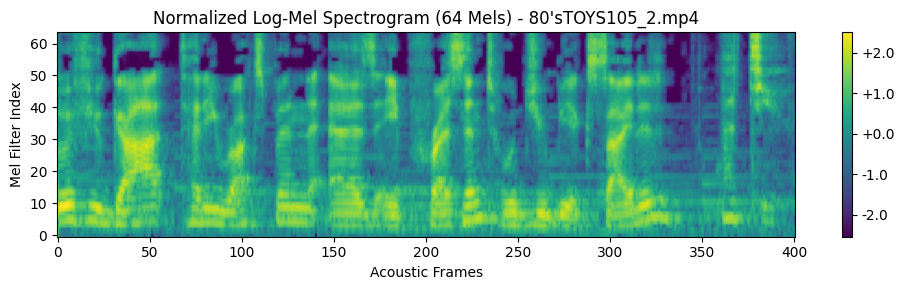

In [9]:
class AudioPreprocessor:
    """
    Extracts, standardizes, and converts raw audio waveforms into normalized Log-Mel Spectrograms.
    """
    def __init__(self, sample_rate=16000, duration_sec=4.0, n_mels=64, n_fft=400, hop_length=160):
        self.sample_rate = sample_rate
        self.target_length = int(sample_rate * duration_sec)
        self.n_mels = n_mels

        self.mel_transform = T.MelSpectrogram(
            sample_rate=sample_rate,
            n_fft=n_fft,
            win_length=n_fft,
            hop_length=hop_length,
            n_mels=n_mels,
            power=2.0
        )

    def process_file(self, file_path):
        try:
            waveform, sr = torchaudio.load(file_path)
        except Exception as e:
            # Fallback for empty or corrupted audio tracks
            waveform = torch.zeros(1, self.target_length)
            sr = self.sample_rate

        # 1. Resample to 16 kHz if needed
        if sr != self.sample_rate:
            resampler = T.Resample(orig_freq=sr, new_freq=self.sample_rate)
            waveform = resampler(waveform)

        # 2. Convert to Mono
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)

        # 3. Standardize duration (pad or center-crop to target_length)
        num_samples = waveform.shape[1]
        if num_samples < self.target_length:
            padding = self.target_length - num_samples
            waveform = F.pad(waveform, (0, padding))
        elif num_samples > self.target_length:
            start_idx = (num_samples - self.target_length) // 2
            waveform = waveform[:, start_idx:start_idx + self.target_length]

        # 4. Compute Log-Mel Spectrogram
        mel_spec = self.mel_transform(waveform) # [1, n_mels, time_steps]
        log_mel = torch.log(mel_spec + 1e-6)

        # 5. Instance Normalization (mean 0, std 1)
        mean = log_mel.mean()
        std = log_mel.std() + 1e-6
        norm_log_mel = (log_mel - mean) / std

        return norm_log_mel

# Test preprocessor on a sample video clip
preprocessor = AudioPreprocessor()
sample_path = split_dfs["train"]["video_path"].iloc[0]
sample_mel = preprocessor.process_file(sample_path)

print(f"Processed Sample File: {os.path.basename(sample_path)}")
print(f"Output Spectrogram Shape: {sample_mel.shape} [Channels, Mel_Bands, Time_Steps]")

# Visualize
plt.figure(figsize=(10, 3))
plt.imshow(sample_mel[0].numpy(), aspect="auto", origin="lower", cmap="viridis")
plt.title(f"Normalized Log-Mel Spectrogram (64 Mels) - {os.path.basename(sample_path)}")
plt.xlabel("Acoustic Frames")
plt.ylabel("Mel Filter Index")
plt.colorbar(format="%+2.1f")
plt.tight_layout()
plt.show()

## 4. PyTorch `EmoReactAudioDataset` & DataLoaders

In [10]:
class EmoReactAudioDataset(Dataset):
    """
    PyTorch Dataset loading audio spectrograms and emotion/valence annotations.
    """
    def __init__(self, df, preprocessor):
        self.df = df.reset_index(drop=True)
        self.preprocessor = preprocessor
        self.emotion_cols = EMOTION_NAMES

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        vid_path = row["video_path"]

        # Extract normalized Log-Mel spectrogram: [1, 64, T_mel]
        log_mel = self.preprocessor.process_file(vid_path)

        # Emotion multi-label target: [8] float tensor
        emotions = torch.tensor(row[self.emotion_cols].values.astype(np.float32))

        # Valence target: [1] float tensor
        valence = torch.tensor([float(row["Valence"])], dtype=torch.float32)

        return {
            "audio": log_mel,
            "emotions": emotions,
            "valence": valence,
            "sample_id": row["video_name"]
        }

# Create Datasets and DataLoaders
train_dataset = EmoReactAudioDataset(split_dfs["train"], preprocessor)
val_dataset = EmoReactAudioDataset(split_dfs["val"], preprocessor)
test_dataset = EmoReactAudioDataset(split_dfs["test"], preprocessor)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=2)

# Verify a single batch
batch = next(iter(train_loader))
print(f"Batch Audio Shape: {batch['audio'].shape} [Batch, 1, 64, T_mel]")
print(f"Batch Emotions Shape: {batch['emotions'].shape} [Batch, 8]")
print(f"Batch Valence Shape: {batch['valence'].shape} [Batch, 1]")

Batch Audio Shape: torch.Size([16, 1, 64, 401]) [Batch, 1, 64, T_mel]
Batch Emotions Shape: torch.Size([16, 8]) [Batch, 8]
Batch Valence Shape: torch.Size([16, 1]) [Batch, 1]


## 5. `AudioEncoder` Neural Architecture


- **Input**: Audio Spectrogram `[B, 1, 64, T_mel]`
- **Output**: Time-aligned feature embedding `[B, T, D_audio]` with:
  - **$T = 16$** (Temporal dimension aligned with video and BiLSTM)
  - **$D_{audio} = 128$** (Feature dimension)

We use a lightweight 2D-CNN feature extractor followed by adaptive temporal pooling to ensure exact `[B, 16, 128]` alignment.

In [12]:
class AudioEncoder(nn.Module):
    """
    Lightweight CNN Audio Encoder mapping Log-Mel spectrograms to time-aligned feature sequences.
    Input:  [Batch, 1, n_mels=64, T_mel]
    Output: [Batch, T=16, D_audio=128]
    """
    def __init__(self, target_steps=16, feature_dim=128):
        super(AudioEncoder, self).__init__()
        self.target_steps = target_steps
        self.feature_dim = feature_dim

        # Conv Block 1
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)) # 64 -> 32
        )

        # Conv Block 2
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)) # 32 -> 16
        )

        # Conv Block 3
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, feature_dim, kernel_size=(3, 3), stride=(1, 1), padding=1),
            nn.BatchNorm2d(feature_dim),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, target_steps)) # Frequency pooled to 1, time pooled to T=16
        )

    def forward(self, x):
        # x shape: [B, 1, 64, T_mel]
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x) # [B, 128, 1, 16]

        # Squeeze frequency dimension: [B, 128, 16]
        x = x.squeeze(2)

        # Permute to standard [B, T, D] convention: [B, 16, 128]
        x = x.permute(0, 2, 1)
        return x

# Smoke test with synthetic tensor (verifying contract)
test_audio = torch.randn(4, 1, 64, 401)
model = AudioEncoder().to(device)
out = model(test_audio.to(device))
print(f"Smoke Test Output Shape: {out.shape} -> Match [4, 16, 128]: {out.shape == torch.Size([4, 16, 128])}")

Smoke Test Output Shape: torch.Size([4, 16, 128]) -> Match [4, 16, 128]: True


## 6. Unimodal Audio Baseline Classifier

To evaluate how informative audio is on its own before multimodal fusion, we add an MLP Emotion Head on top of the temporal representations.

In [13]:
class AudioEmotionBaseline(nn.Module):
    """
    Unimodal Audio Emotion Model.
    AudioEncoder -> Temporal Mean Pooling -> MLP Emotion Head (8 Logits)
    """
    def __init__(self, target_steps=16, feature_dim=128, num_emotions=8):
        super(AudioEmotionBaseline, self).__init__()
        self.encoder = AudioEncoder(target_steps=target_steps, feature_dim=feature_dim)
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_emotions)
        )

    def forward(self, x):
        # x: [B, 1, 64, T_mel]
        feat_seq = self.encoder(x) # [B, 16, 128]
        pooled = torch.mean(feat_seq, dim=1) # [B, 128]
        logits = self.classifier(pooled) # [B, 8]
        return logits, feat_seq

# Calculate pos_weight for BCE to handle class imbalance
train_emotions = split_dfs["train"][EMOTION_NAMES].values
pos_counts = train_emotions.sum(axis=0)
neg_counts = len(train_emotions) - pos_counts
pos_weight = torch.tensor(neg_counts / np.maximum(pos_counts, 1), dtype=torch.float32).to(device)
print("Class Imbalance pos_weights:", {EMOTION_NAMES[i]: round(float(pos_weight[i]), 2) for i in range(8)})

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
audio_model = AudioEmotionBaseline().to(device)
optimizer = torch.optim.AdamW(audio_model.parameters(), lr=1e-3, weight_decay=1e-4)

Class Imbalance pos_weights: {'Curiosity': 1.92, 'Uncertainty': 2.27, 'Excitement': 2.0, 'Happiness': 0.93, 'Surprise': 2.79, 'Disgust': 6.2, 'Fear': 24.41, 'Frustration': 7.15}


## 7. Baseline Training & Evaluation Loop (10 Epochs)

In [14]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    for batch in loader:
        audio = batch["audio"].to(device)
        labels = batch["emotions"].to(device)

        optimizer.zero_grad()
        logits, _ = model(audio)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * audio.size(0)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for batch in loader:
        audio = batch["audio"].to(device)
        labels = batch["emotions"].to(device)

        logits, _ = model(audio)
        loss = criterion(logits, labels)
        total_loss += loss.item() * audio.size(0)

        probs = torch.sigmoid(logits)
        all_preds.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

    all_preds = np.vstack(all_preds)
    all_labels = np.vstack(all_labels)

    # Multi-label Macro-F1 at 0.5 threshold
    binary_preds = (all_preds >= 0.5).astype(int)
    macro_f1 = f1_score(all_labels, binary_preds, average="macro", zero_division=0)

    return total_loss / len(loader.dataset), macro_f1, all_preds, all_labels

# Run training for 10 epochs
print("Starting Audio Baseline Training...")
history = {"train_loss": [], "val_loss": [], "val_f1": []}
best_val_f1 = 0.0

for epoch in range(1, 11):
    tr_loss = train_one_epoch(audio_model, train_loader, optimizer, criterion)
    val_loss, val_f1, _, _ = evaluate(audio_model, val_loader, criterion)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(audio_model.encoder.state_dict(), "best_audio_encoder.pt")

    print(f"Epoch [{epoch:02d}/10] | Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro-F1: {val_f1:.4f}")

print(f"Best Validation Macro-F1: {best_val_f1:.4f}")

Starting Audio Baseline Training...
Epoch [01/10] | Train Loss: 1.0345 | Val Loss: 1.0227 | Val Macro-F1: 0.1614
Epoch [02/10] | Train Loss: 1.0244 | Val Loss: 1.0213 | Val Macro-F1: 0.1910
Epoch [03/10] | Train Loss: 1.0125 | Val Loss: 1.0109 | Val Macro-F1: 0.2894
Epoch [04/10] | Train Loss: 1.0104 | Val Loss: 1.0088 | Val Macro-F1: 0.3751
Epoch [05/10] | Train Loss: 0.9941 | Val Loss: 1.0000 | Val Macro-F1: 0.3030
Epoch [06/10] | Train Loss: 0.9758 | Val Loss: 0.9872 | Val Macro-F1: 0.3920
Epoch [07/10] | Train Loss: 0.9691 | Val Loss: 0.9919 | Val Macro-F1: 0.3105
Epoch [08/10] | Train Loss: 0.9551 | Val Loss: 0.9997 | Val Macro-F1: 0.3731
Epoch [09/10] | Train Loss: 0.9376 | Val Loss: 0.9860 | Val Macro-F1: 0.3539
Epoch [10/10] | Train Loss: 0.9548 | Val Loss: 1.1342 | Val Macro-F1: 0.2686
Best Validation Macro-F1: 0.3920


## 8. Test Set Evaluation & Per-Class Metrics


=== Final Test Evaluation ===
Test Loss: 0.9802 | Test Macro-F1: 0.3768



,Emotion,Test_F1,Test_Support
0,Curiosity,0.5161,131
1,Uncertainty,0.4895,115
2,Excitement,0.4695,118
3,Happiness,0.3232,211
4,Surprise,0.4693,105
5,Disgust,0.3186,46
6,Fear,0.1641,20
7,Frustration,0.2645,38


/tmp/ipykernel_573/2702771157.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Emotion", y="Test_F1", palette="mako")


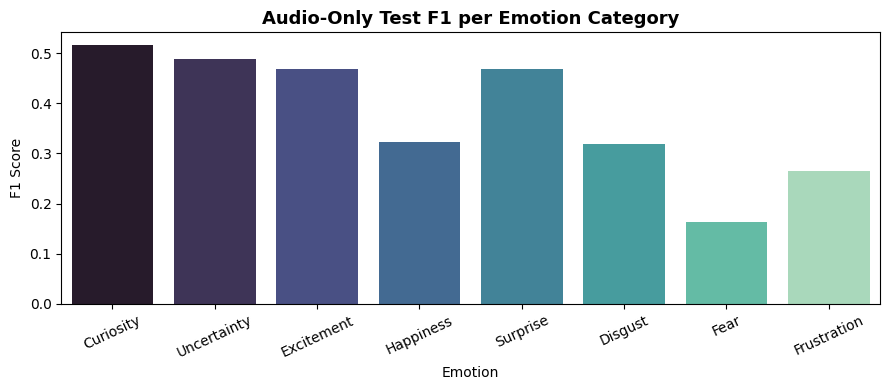

In [15]:
# Load best encoder weights
if os.path.exists("best_audio_encoder.pt"):
    audio_model.encoder.load_state_dict(torch.load("best_audio_encoder.pt"))

test_loss, test_f1, test_preds, test_labels = evaluate(audio_model, test_loader, criterion)
print(f"\n=== Final Test Evaluation ===")
print(f"Test Loss: {test_loss:.4f} | Test Macro-F1: {test_f1:.4f}\n")

# Per-class F1-scores
test_binary = (test_preds >= 0.5).astype(int)
per_class_f1 = f1_score(test_labels, test_binary, average=None, zero_division=0)
results_df = pd.DataFrame({
    "Emotion": EMOTION_NAMES,
    "Test_F1": np.round(per_class_f1, 4),
    "Test_Support": test_labels.sum(axis=0).astype(int)
})
display(results_df)

# Plot per-class test F1
plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x="Emotion", y="Test_F1", palette="mako")
plt.title("Audio-Only Test F1 per Emotion Category", fontsize=13, fontweight="bold")
plt.ylabel("F1 Score")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 9. Feature Caching for Multimodal Fusion

To prepare for **Stage 3 (Multimodal Fusion)**, we extract and cache the audio embeddings for all clips:
- Output representation shape: `[N_samples, 16, 128]`
- Saved to `data/features/audio_features.pt`.

In [16]:
os.makedirs("data/features", exist_ok=True)

@torch.no_grad()
def extract_features(model, loader):
    model.eval()
    all_features = []
    all_sample_ids = []
    for batch in loader:
        audio = batch["audio"].to(device)
        feats = model.encoder(audio) # [B, 16, 128]
        all_features.append(feats.cpu())
        all_sample_ids.extend(batch["sample_id"])
    return torch.cat(all_features, dim=0), all_sample_ids

print("Extracting audio representations for all splits...")
train_feats, train_ids = extract_features(audio_model, train_loader)
val_feats, val_ids = extract_features(audio_model, val_loader)
test_feats, test_ids = extract_features(audio_model, test_loader)

print(f"Train Audio Features: {train_feats.shape} [432, 16, 128]")
print(f"Val Audio Features:   {val_feats.shape}   [303, 16, 128]")
print(f"Test Audio Features:  {test_feats.shape}  [367, 16, 128]")

# Save cached features
feature_dict = {
    "train": {"features": train_feats, "sample_ids": train_ids},
    "val": {"features": val_feats, "sample_ids": val_ids},
    "test": {"features": test_feats, "sample_ids": test_ids},
    "feature_dim": 128,
    "temporal_steps": 16
}
torch.save(feature_dict, "data/features/audio_features.pt")
print("\nSuccessfully cached audio features to data/features/audio_features.pt!")

Extracting audio representations for all splits...
Train Audio Features: torch.Size([432, 16, 128]) [432, 16, 128]
Val Audio Features:   torch.Size([303, 16, 128])   [303, 16, 128]
Test Audio Features:  torch.Size([367, 16, 128])  [367, 16, 128]

Successfully cached audio features to data/features/audio_features.pt!


## 10. Summary & Completion Checklist

- [x] Audio standardized to 16 kHz mono.
- [x] 64-band Log-Mel Spectrogram pipeline established.
- [x] `AudioEncoder` CNN producing `[B, 16, 128]` validated.
- [x] Audio-only baseline trained and evaluated with BCE with `pos_weight`.
- [x] Extracted audio feature tensors cached for Stage 3 Multimodal Fusion!